# CECS 427 — Assignment 5
## Matching Markets (Perfect Matchings, Constricted Sets, Market-Clearing Prices)

**Submission:** upload this notebook (`.ipynb`) with code + short written answers + required diagrams.

### What to submit
- Completed code in the provided cells
- Clear outputs (print key results, labeled)
- Required diagrams:
  - bipartite graphs with labeled sides
  - matching highlighted (when asked)
  - preferred-seller graphs (when asked)
- Short explanations in Markdown where prompted

> Some cells include commented “debug prints.” They do not run unless you uncomment them.


In [1]:
# Imports
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from itertools import combinations
from collections import deque


### Variable Guide (quick reference)

Bipartite graphs / matchings:
- `U`: right-side nodes (e.g., students or buyers)
- `V`: left-side nodes (e.g., internship positions or sellers)
- `G`: a bipartite graph (undirected)
- `edges`: list of acceptable pairs `(u, v)` where `u ∈ U`, `v ∈ V`
- `M`: a matching (often stored as dict `u -> v` on the U side)
- `S`: a subset of nodes on one side of the graph
- `N(S)`: neighbor set of `S` on the opposite side

Prices / preferred-seller graphs:
- `Vmat.loc[buyer, seller]`: valuation of a buyer for a seller’s item
- `prices[seller]`: current price of seller/item
- `payoff(buyer, seller) = valuation - price`
- `pref[buyer]`: list of preferred sellers (ties allowed)

Augmentation:
- `pairU[u]`: matched partner of u (or None)
- `pairV[v]`: matched partner of v (or None)
- `dist[u]`: BFS layer distance for alternating-path BFS



## Part A — Internship Position Assignment (Warm-up)

A university is helping five students find summer internships. Five internship positions are available, each in a different technical field.

Each student has a list of acceptable positions based on their skills and interests. Each student can accept at most one position, and each position can be assigned to at most one student.

**Students (U):**
Nina, Omar, Priya, Quinn, Rafael

**Internship Positions (V):**
Backend, DataScience, Cybersecurity, UIUX, Cloud

**Acceptable positions:**
- Nina: Backend, DataScience
- Omar: Cybersecurity, UIUX
- Priya: DataScience, Cybersecurity
- Quinn: UIUX, Cloud
- Rafael: Backend, Cloud

An edge between a student and a position indicates that the student is qualified for and willing to accept that position.

### Tasks

**A1. Build the bipartite graph**
- Create a bipartite graph with students on the right and internship positions on the left.
- Add edges representing acceptable assignments.
- Draw the graph with labeled nodes.

**A2. Find a maximum matching**
- Use NetworkX to compute a maximum matching.
- Report the matching size.
- Determine whether a perfect matching exists.
- Briefly explain what a perfect matching means in this internship assignment problem.

**A3. Visualize the assignment**
- If a perfect matching exists, highlight the matched edges.
- Print the final student-to-position assignments.
- Verify that each student receives one acceptable position and no position is assigned more than once.



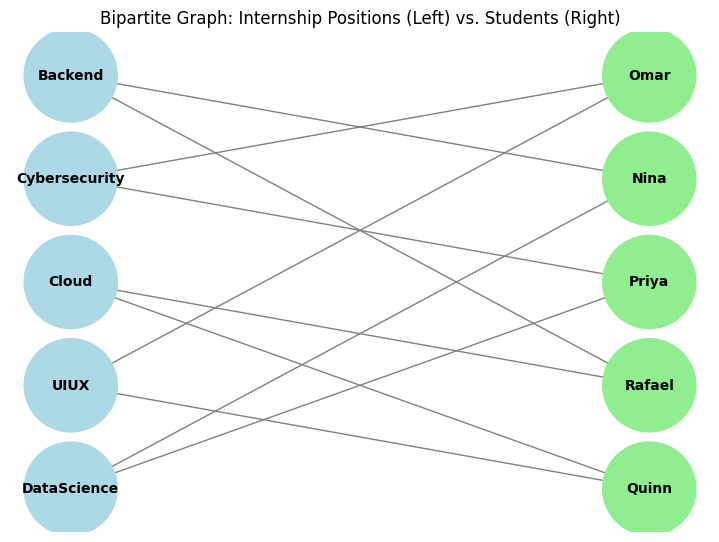

In [10]:

# A1 — Build + draw Dataset A

U = ["Nina", "Omar", "Priya", "Quinn", "Rafael"]

V = ["Backend", "DataScience", "Cybersecurity", "UIUX", "Cloud"]

edges_A = [
    ("Nina", "Backend"), ("Nina", "DataScience"),
    ("Omar", "Cybersecurity"), ("Omar", "UIUX"),
    ("Priya", "DataScience"), ("Priya", "Cybersecurity"),
    ("Quinn", "UIUX"), ("Quinn", "Cloud"),
    ("Rafael", "Backend"), ("Rafael", "Cloud"),
]

# TODO:
# 1) Build bipartite graph G_A (bipartite=0 for U, bipartite=1 for V)
# 2) Add edges_A
# 3) Draw using nx.bipartite_layout(G_A, U)

G_A = nx.Graph()

G_A.add_nodes_from(U, biparte= 0)
G_A.add_nodes_from(V, biparte= 1)
G_A.add_edges_from(edges_A)

pos = nx.bipartite_layout(G_A, V)

plt.figure(figsize=(7, 5))
node_colors = ["lightblue" if n in V else "lightgreen" for n in G_A.nodes()]

nx.draw(
    G_A,
    pos,
    with_labels=True,
    node_color=node_colors,
    node_size=4500,
    font_size=10,
    font_weight="bold",
    edge_color="gray",
)
plt.title("Bipartite Graph: Internship Positions (Left) vs. Students (Right)")
plt.show()


In [11]:

# A2 — Maximum matching + perfect matching check

# 1) Compute maximum matching
matching_A = nx.algorithms.bipartite.matching.maximum_matching(G_A, top_nodes=U)

# 2) Convert to assignment dict: assign_A[u] = matched internship position
assign_A = {u: matching_A[u] for u in U if u in matching_A}

# 3) Print matching size and whether it is perfect
matching_size = len(assign_A)
is_perfect = (matching_size == len(U)) and (matching_size == len(V))

print(f"Matching size: {matching_size}")
print(f"Perfect matching exists? {is_perfect}")
print("Assignments:", assign_A)

Matching size: 5
Perfect matching exists? True
Assignments: {'Nina': 'Backend', 'Omar': 'Cybersecurity', 'Priya': 'DataScience', 'Quinn': 'UIUX', 'Rafael': 'Cloud'}


A perfect matching means that every single student in U is matched to a unique, acceptable internship position in V, and every internship position is filled by exactly one student—leaving zero unmatched students and zero unfilled positions.

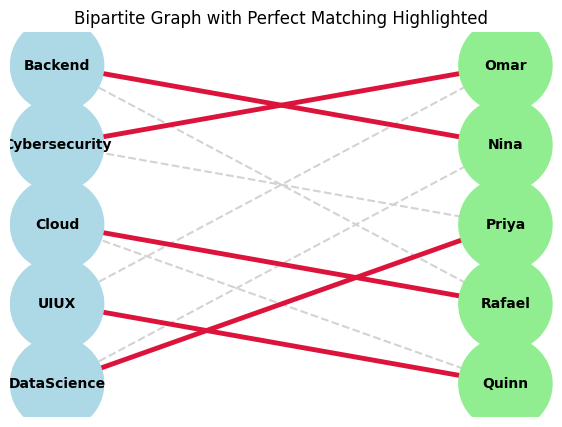

Final Student-to-Position Assignments:
  Nina -> Backend
  Omar -> Cybersecurity
  Priya -> DataScience
  Quinn -> UIUX
  Rafael -> Cloud

Verification Checks:
  Every student assigned exactly one position: True
  Every assigned position is acceptable: True
  No position assigned more than once: True


In [13]:

# A3 — Plot with matched edges highlighted

# TODO:
# If perfect matching exists:
# - Draw the same bipartite graph again
# - Highlight matched edges (thicker or different color)
# - Print matched pairs (student -> internship position)
# - Verify that each student and position is used exactly once

if is_perfect:
    # Build set of matched edges (normalized as frozensets since G_A is undirected)
    matched_edges = list(assign_A.items())
    matched_set = {frozenset(e) for e in matched_edges}
    unmatched_edges = [e for e in G_A.edges() if frozenset(e) not in matched_set]

    # 1) Draw the same bipartite graph again with matched edges highlighted
    plt.figure(figsize=(7, 5))
    node_colors = ["lightblue" if n in V else "lightgreen" for n in G_A.nodes()]

    nx.draw_networkx_nodes(G_A, pos, node_color=node_colors, node_size=4500)
    nx.draw_networkx_labels(G_A, pos, font_size=10, font_weight="bold")

    # Draw unmatched edges faintly and matched edges thickly in red
    nx.draw_networkx_edges(
        G_A, pos, edgelist=unmatched_edges, edge_color="lightgray", width=1.5, style="dashed"
    )
    nx.draw_networkx_edges(
        G_A, pos, edgelist=matched_edges, edge_color="crimson", width=3.5
    )

    plt.title("Bipartite Graph with Perfect Matching Highlighted")
    plt.axis("off")
    plt.show()

    # 2) Print matched pairs (student -> internship position)
    print("Final Student-to-Position Assignments:")
    for student in U:
        print(f"  {student} -> {assign_A[student]}")

    # 3) Verify that each student receives one acceptable position and no position is used twice
    acceptable_set = {frozenset(e) for e in edges_A}
    all_students_matched = set(assign_A.keys()) == set(U)
    all_edges_acceptable = all(frozenset((u, v)) in acceptable_set for u, v in assign_A.items())
    unique_positions_used = len(set(assign_A.values())) == len(V)

    print("\nVerification Checks:")
    print(f"  Every student assigned exactly one position: {all_students_matched}")
    print(f"  Every assigned position is acceptable: {all_edges_acceptable}")
    print(f"  No position assigned more than once: {unique_positions_used}")
else:
    print("No perfect matching exists.")


---  
## Part B — Market-Clearing Prices via Preferred-Seller Graphs

At prices `p[seller]`, buyer payoff is:
`payoff(buyer, seller) = valuation(buyer, seller) − p[seller]`
(If all payoffs are negative, the buyer prefers buying nothing.)

Each buyer points to their **preferred seller(s)** (max payoff; ties allowed).  
Prices are **market-clearing** iff the preferred-seller graph has a **perfect matching** (matches all buyers).

### Dataset B (4 buyers × 4 sellers)
Buyers = `["b1","b2","b3","b4"]`  
Sellers = `["s1","s2","s3","s4"]`

Valuation matrix `Vmat`:

|     | s1 | s2 | s3 | s4 |
|-----|----|----|----|----|
| b1  |  6 |  1 | 10 |  4 |
| b2  |  8 |  3 |  9 |  2 |
| b3  |  5 |  4 |  7 |  9 |
| b4  |  7 |  8 |  6 |  3 |

### Tasks
**B1. Preferred sellers at fixed prices.**
Given prices `p0 = {"s1": 0, "s2": 0, "s3": 2, "s4": 1}`, compute preferred sellers for each buyer, build the preferred-seller graph, and draw it.


**B2. Market-clearing check.**  
Use NetworkX to check whether the preferred-seller graph has a perfect matching (matches all buyers). If yes, print one matching.

**B3. Auction / price-adjustment procedure (from scratch).**  
Implement the iterative procedure:
1) start with all prices = 0 (normalize so min price = 0 each round)  
2) build preferred-seller graph  
3) if perfect matching exists → stop  
4) else find a constricted set of buyers S where |S| > |N(S)| (neighbors are sellers)  
5) increase price of each seller in N(S) by 1  
6) normalize prices so min price = 0  
Print prices each round and draw the preferred-seller graph for at least the first 2 rounds.


In [ ]:

# B0 — Dataset B

buyers = ["b1", "b2", "b3", "b4"]
sellers = ["s1", "s2", "s3", "s4"]

Vmat = pd.DataFrame(
    [[6, 1, 10, 4],
     [8, 3, 9, 2],
     [5, 4, 7, 9],
     [7, 8, 6, 3]],
    index=buyers, columns=sellers
)

p0 = {"s1": 0, "s2": 0, "s3": 2, "s4": 1}

Vmat



,s1,s2,s3,s4
b1,6,1,10,4
b2,8,3,9,2
b3,5,4,7,9
b4,7,8,6,3


In [ ]:
# B1 — Preferred sellers + preferred-seller graph at prices p0

def preferred_sellers(Vmat, prices):
    """Return dict buyer -> list of preferred sellers (ties allowed).
    If all payoffs < 0, return [] for that buyer.
    """
    # TODO
    pass

def build_preferred_graph(buyers, sellers, pref):
    """Build a bipartite graph with edges buyer -> preferred sellers."""
    # TODO
    pass

# TODO:
# pref = preferred_sellers(Vmat, p0)
# G_pref = build_preferred_graph(buyers, sellers, pref)
# draw (buyers right, sellers left) with nx.bipartite_layout


In [ ]:
# B2 — Market-clearing check (perfect matching in preferred graph)

# TODO:
# - Use maximum_matching on G_pref with top_nodes=buyers
# - Extract buyer->seller assignment
# - Print whether market-clearing (matched all buyers)
# - If yes, print one assignment


In [ ]:
# B3 — Auction procedure to find market-clearing prices

def normalize_prices(prices):
    """Shift prices so the minimum becomes 0."""
    # TODO
    pass

def neighbor_set_side(G, S):
    """Neighbors of a set S in an undirected graph."""
    # TODO
    pass

def find_constricted_set_on_buyers(G_pref, buyers):
    """Find S ⊆ buyers such that |S| > |N(S)| (neighbors are sellers).
    Return (S, N_of_S) or (None, None).
    """
    # TODO: brute force is fine here because there are only 4 buyers
    pass

def auction_market_clearing_prices(Vmat, buyers, sellers, max_rounds=30):
    """Run price-adjustment until market-clearing prices are found.

    Return:
      prices (dict), final_graph (nx.Graph), matching (dict buyer->seller), history (list of round info)
    """
    # TODO (suggested steps):
    # 1) init prices = 0
    # 2) repeat:
    #   a) build preferred graph
    #   b) check perfect matching
    #   c) if not perfect: find constricted set S and N(S)
    #   d) raise prices for sellers in N(S)
    #   e) normalize
    pass

# TODO:
# prices_star, G_star, M_star, hist = auction_market_clearing_prices(Vmat, buyers, sellers)
# print(prices_star)
# print(M_star)


### B Discussion (4–6 sentences)
Why can raising prices help remove “over-demanded” sellers and allow a perfect matching in the preferred-seller graph?


---  
## Part C — Full Bipartite Matching Algorithm (Alternating BFS + Augmenting Paths)

In lecture, the perfect-matching routine repeatedly:
1) runs an **alternating BFS** starting from all currently-unmatched nodes on the right side,  
2) if the BFS reaches an unmatched node on the left side, it reconstructs an **augmenting path** and enlarges the matching,  
3) otherwise, it stops and returns a **certificate** (a constricted set) showing why a perfect matching is impossible.

You will implement this algorithm:
- **Alternating BFS** (U → V via *unmatched* edges, V → U via *matched* edges)
- **Augment** along one found shortest augmenting path
- If no augmenting path exists, return a **constricted set** `S ⊆ U` with `|S| > |N(S)|`

### Your tasks
**C1. Implement the alternating BFS routine** to either find an augmenting path endpoint or return reachable sets.  
**C2. Implement augmentation** that runs BFS/augment until:
- perfect matching found, OR
- BFS fails and you return a constricted set certificate.

**C3. Test on two given test cases** below and report:
- perfect matching exists?  
- if yes: show matching size and print first 8 pairs  
- if not: show matching size and print one constricted set `S` and its neighbor set `N(S)` (sizes + a few members)

> Keep output readable: do not print huge dictionaries; summarize.


In [ ]:
# Two bipartite test cases (do not change)

# Case 1: Test Case 1
U1 = [f"U{i}" for i in range(1, 13)]
V1 = [f"V{i}" for i in range(1, 13)]

edges_case1 = []
for i in range(12):
    u = U1[i]
    v_same = V1[i]
    v_next = V1[(i+1) % 12]
    edges_case1.append((u, v_same))
    edges_case1.append((u, v_next))
edges_case1 += [("U1","V3"), ("U2","V5"), ("U7","V9"), ("U10","V12")]
edges_case1 = list(dict.fromkeys(edges_case1))
v_permutation = {
    f"V{i}": f"V{((i + 3) % 12) + 1}"
    for i in range(1, 13)
}

edges_case1 = [
    (u, v_permutation[v])
    for u, v in edges_case1
]


# Case 2: Test Case 2
U2 = [f"A{i}" for i in range(1, 13)]
V2 = [f"B{i}" for i in range(1, 13)]

edges_case2 = []
# Constricted group: A1..A5 initially connect only to B1..B4.
# After relabeling, they connect only to B6..B9.
for u in ["A1","A2","A3","A4","A5"]:
    for v in ["B1","B2","B3","B4"]:
        edges_case2.append((u, v))

# Remaining nodes have richer connections
for i in range(6, 13):
    u = f"A{i}"
    edges_case2 += [(u, f"B{i}"), (u, f"B{(i%12)+1}"), (u, "B12")]

edges_case2.append(("A6", "B5"))
edges_case2 = list(dict.fromkeys(edges_case2))

# Relabel B nodes while preserving the constricted set
b_permutation = {
    f"B{i}": f"B{((i + 4) % 12) + 1}"
    for i in range(1, 13)
}

edges_case2 = [
    (u, b_permutation[v])
    for u, v in edges_case2
]


def build_adj(U, edges):
    adj = {u: [] for u in U}
    for (u,v) in edges:
        if u in adj:
            adj[u].append(v)
    for u in adj:
        adj[u] = list(dict.fromkeys(adj[u]))
    return adj


In [ ]:
# C1 — Alternating BFS to find an augmenting path

def alternating_bfs(U, V, adj, pairU, pairV):
    """Run alternating BFS from all free (unmatched) u in U.

    Alternation rule:
    - From U: traverse ONLY UNMATCHED edges (u -> v where pairU[u] != v)
    - From V: traverse ONLY MATCHED edges (v -> u where pairV[v] = u)

    Returns
    -------
    found_v : str or None
        A free/unmatched v in V reached by BFS (end of an augmenting path), or None if none exists.
    parentU : dict
        parentU[u] = v that reached u via a matched edge (used for path reconstruction)
    parentV : dict
        parentV[v] = u that reached v via an unmatched edge
    reachableU : set
    reachableV : set
        Nodes reached by BFS (useful for certificate when found_v is None).
    """
    # TODO
    pass


In [ ]:
# C2 — Augmentation

def augment_matching(found_v, pairU, pairV, parentU, parentV):
    """Augment along the discovered alternating path that ends at found_v.

    You can reconstruct backwards:
    found_v <- parentV[v] = u <- parentU[u] = previous_v <- ... until u is free.
    Update pairU and pairV along the path (flip matched/unmatched edges).
    """
    # TODO
    pass

def perfect_matching_or_certificate(U, V, adj):
    """Compute a maximum matching using alternating BFS + augmentation.

    Returns
    -------
    pairU : dict[u] -> v or None
    pairV : dict[v] -> u or None
    matching_size : int
    certificate : tuple or None
        If perfect matching does NOT exist, return (S, NS) where S ⊆ U and NS = N(S),
        and must satisfy |S| > |NS|. If perfect matching exists, return None.
    """
    # TODO (suggested structure):
    # 1) initialize pairU/pairV to None
    # 2) repeat:
    #    a) run alternating_bfs(...)
    #    b) if found_v is None: return maximum matching + certificate (reachableU, reachableV)
    #    c) else augment and continue
    # 3) if matching_size == len(U): perfect matching found
    pass


In [ ]:
# C3 — Run your implementation on both cases

# TODO:
# Case 1
# adj1 = build_adj(U1, edges_case1)
# pairU1, pairV1, m1, cert1 = perfect_matching_or_certificate(U1, V1, adj1)
# print(m1, m1 == len(U1))

# Case 2
# adj2 = build_adj(U2, edges_case2)
# pairU2, pairV2, m2, cert2 = perfect_matching_or_certificate(U2, V2, adj2)
# print(m2, m2 == len(U2))

# If a perfect matching exists, print the first 8 matched pairs.
# Otherwise, print the constricted set S and its neighbor set N(S).
# Include their sizes and a few members.

### C Discussion (4–6 sentences)
What role does alternating BFS play in finding augmenting paths? How does its layer-by-layer search differ from a DFS-based approach? What happens when no augmenting path can be found?